<a href="https://colab.research.google.com/github/satapathysanchita783-afk/Machine-Learning-using-Colab/blob/main/House_Price_Prediction_using_Multiple_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
data = {
    'Area': [
        800, 1000, 1200, 1500, 1800,
        2000, 2200, 2500, 2800, 3000,
        3200, 3500, 3800, 4000, 4200, 4500,
        1100, 1600, 2100, 2700, 3300, 3900
    ],

    'Bedrooms': [
        1, 2, 2, 3, 3, 3, 4, 4, 4, 5,
        5, 5, 6, 6, 6, 6, 2, 3, 3, 4,
        5, 5
    ],

    'Age': [
        20, 15, 12, 10, 8, 5, 7, 6, 5, 4,
        3, 4, 3, 2, 2, 1, 18, 12, 9, 7,
        6, 3
    ],

    'Price': [
        24, 32, 38, 48, 58, 65, 69, 80,
        88, 96, 103, 113, 122, 130, 136, 146,
        34, 51, 66, 85, 106, 125
    ]
}

df = pd.DataFrame(data)

print(df)

    Area  Bedrooms  Age  Price
0    800         1   20     24
1   1000         2   15     32
2   1200         2   12     38
3   1500         3   10     48
4   1800         3    8     58
5   2000         3    5     65
6   2200         4    7     69
7   2500         4    6     80
8   2800         4    5     88
9   3000         5    4     96
10  3200         5    3    103
11  3500         5    4    113
12  3800         6    3    122
13  4000         6    2    130
14  4200         6    2    136
15  4500         6    1    146
16  1100         2   18     34
17  1600         3   12     51
18  2100         3    9     66
19  2700         4    7     85
20  3300         5    6    106
21  3900         5    3    125


In [ ]:
df.shape

(22, 4)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Area      22 non-null     int64
 1   Bedrooms  22 non-null     int64
 2   Age       22 non-null     int64
 3   Price     22 non-null     int64
dtypes: int64(4)
memory usage: 836.0 bytes


In [ ]:
df.describe()

,Area,Bedrooms,Age,Price
count,22.000000,22.000000,22.000000,22.000000
mean,2577.272727,3.954545,7.363636,82.500000
std,1128.813882,1.495303,5.242187,36.835219
min,800.000000,1.000000,1.000000,24.000000
25%,1650.000000,3.000000,3.250000,52.750000
50%,2600.000000,4.000000,6.000000,82.500000
75%,3450.000000,5.000000,9.750000,111.250000
max,4500.000000,6.000000,20.000000,146.000000


In [ ]:
df.isnull().sum()

,0
Area,0
Bedrooms,0
Age,0
Price,0


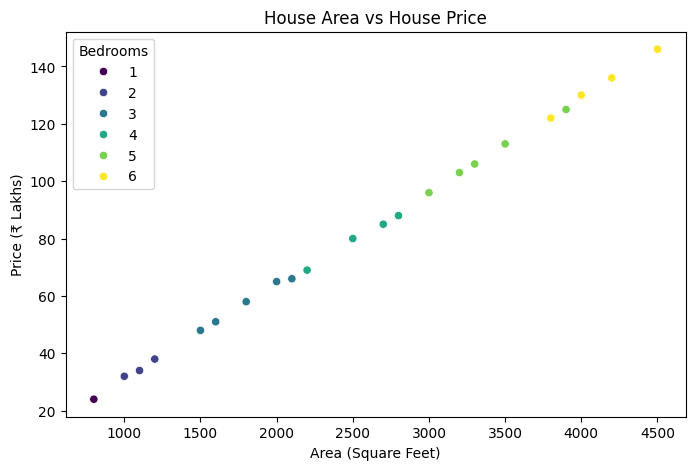

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Area',
    y='Price',
    hue='Bedrooms',
    palette='viridis',
    #s=100
)

plt.title('House Area vs House Price')
plt.xlabel('Area (Square Feet)')
plt.ylabel('Price (₹ Lakhs)')
plt.show()

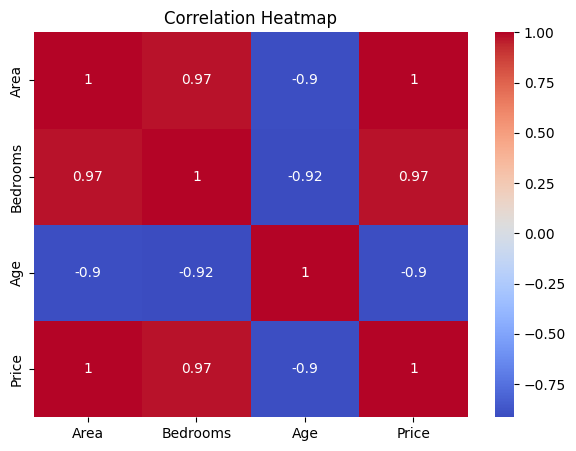

In [ ]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    #fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [ ]:
df.columns

Index(['Area', 'Bedrooms', 'Age', 'Price'], dtype='object')

In [ ]:
#Select X and y
X = df[['Area', 'Bedrooms', 'Age']]
y = df['Price']

#print("Input features (X):")
#print(X.head())

#print("\nTarget variable (y):")
#print(y.head())

In [ ]:
#Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)



In [ ]:
print("Training input size:", X_train.shape)
print("Testing input size:", X_test.shape)

print("Training output size:", y_train.shape)
print("Testing output size:", y_test.shape)

Training input size: (17, 3)
Testing input size: (5, 3)
Training output size: (17,)
Testing output size: (5,)


In [ ]:
X_test

,Area,Bedrooms,Age
0,800,1,20
13,4000,6,2
8,2800,4,5
1,1000,2,15
15,4500,6,1


In [ ]:
y_test   (actual testing data / output)

,Price
0,24
13,130
8,88
1,32
15,146


In [ ]:
#Create Linear Regression Model
model = LinearRegression()

In [ ]:
#Trained the model
model.fit(X_train,y_train)

LinearRegression()

In [ ]:
#Predict
y_prediction=model.predict(X_test)
y_prediction

array([ 24.02826275, 128.61225634,  89.89379046,  30.95259035,
       144.84493064])

In [ ]:
model_price_prediction=model.predict([[4300,4,5]])
print(model_price_prediction)

[138.20723145]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [ ]:
model.coef_

array([ 0.03220896, -0.15843442, -0.12819398])

In [ ]:
print(model.intercept_)

0.9834082181885577


In [ ]:
y1=(0.03220896 * 4300  + -0.15843442 * 4  +  -0.12819398 * 5)  + 0.9834082181885577
print(y1)

138.2072286381886


In [ ]:
#Evaluate Model Performance
mae = mean_absolute_error(y_test, y_prediction)

mse = mean_squared_error(y_test, y_prediction)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_prediction)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R² Score:", round(r2, 4))

Mean Absolute Error (MAE): 1.1
Mean Squared Error (MSE): 1.59
Root Mean Squared Error (RMSE): 1.26
R² Score: 0.9994


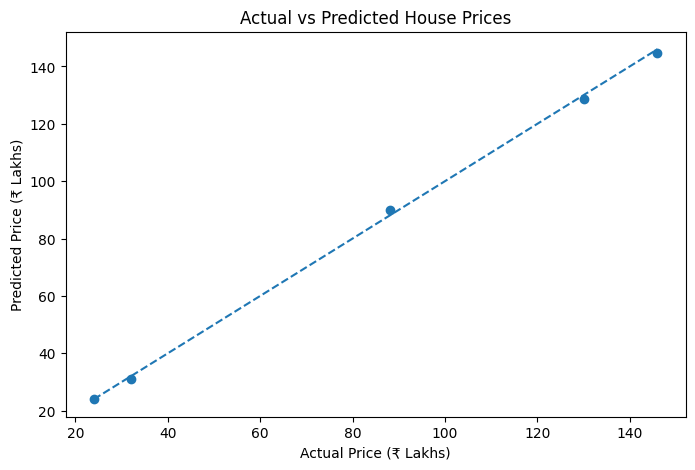

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    y_prediction,
    #s=100
)

min_value = min(y_test.min(), y_prediction.min())
max_value = max(y_test.max(), y_prediction.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.xlabel('Actual Price (₹ Lakhs)')
plt.ylabel('Predicted Price (₹ Lakhs)')
plt.title('Actual vs Predicted House Prices')
plt.show()

Student practice exercises

1. Add a Bathrooms column to the dataset.
2. Use four input features instead of three.
3. Predict the price of a 3,000 sq. ft. house with four bedrooms and an age of eight years.
4. Compare MAE and R² when using different test_size values.
5. Load a CSV file using pd.read_csv() instead of manually creating the dataset.
6. Research multicollinearity and investigate whether highly correlated input features affect coefficient interpretation.